# Generalized Railway Platform Allocation — Final Encoding & Feasibility Investigation (V10)

**Purpose:** final bounded experiment before closing the computational study. V10 reuses the V9/V9.1 generalized synthetic railway generator and the same six-platform model. It compares **one-hot** and **domain-wall** encodings on matched instances, using SA and SQA with matched read/sweep/repeat budgets. It records all constraint violations independently and evaluates a separate sample-preference-guided repair procedure.

**Scope:** five representative sizes (64, 256, 512, 1,024, 2,048 trains), three synthetic difficulty configurations, multiple independent seeds, and a small domain-wall platform-label ordering probe. V10 does not increase the maximum train count. After V10, the planned computational study is complete unless a correctness defect is discovered.

**Interpretation:** raw sampler feasibility is the primary algorithmic result. Repaired results are separate post-processing results and must never be merged into raw feasibility. OpenJij SQA is a classical simulation, not quantum hardware. All train data are synthetic and station-independent.

**Domain-wall detail:** each train uses a chain whose number of states equals that train's eligible-platform count. This builds eligibility into the domain and avoids a separate eligibility penalty. Its wall penalty is bounded using the maximum conflict degree, the feasible upper bound, and the exact negative-conflict contribution per wall rise.

## 0. Environment setup
Run if needed, then restart the kernel.

In [1]:
%pip install -q openjij numpy pandas matplotlib psutil

Note: you may need to restart the kernel to use updated packages.


## 1. Imports and machine information

In [2]:
import sys, platform, time, math, json, itertools, random, importlib.metadata, warnings, os, gc
from pathlib import Path
from typing import Dict, List, Tuple, Optional, Any
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

try:
    import openjij as oj
except ImportError as exc:
    raise ImportError("OpenJij is required. Install it in this notebook kernel, then restart the kernel.") from exc

try:
    import psutil
    RAM_GB = round(psutil.virtual_memory().total / 1024**3, 2)
except Exception:
    psutil = None
    RAM_GB = None
try:
    OPENJIJ_VERSION = importlib.metadata.version("openjij")
except Exception:
    OPENJIJ_VERSION = getattr(oj, "__version__", "version not exposed")

print("Python:", sys.version.split()[0])
print("OS:", platform.platform())
print("CPU:", platform.processor() or "not exposed")
print("RAM (GB):", RAM_GB)
print("OpenJij:", OPENJIJ_VERSION)

Python: 3.12.12
OS: Windows-11-10.0.26300-SP0
CPU: Intel64 Family 6 Model 143 Stepping 8, GenuineIntel
RAM (GB): 127.65
OpenJij: 0.12.2


## 2. Pre-registered V10 design and execution mode

Run `PILOT` first. Only after reviewing the pilot should you switch to `FULL` and restart the kernel. Output folders are mode-specific to prevent pilot outputs being overwritten.

In [3]:
# V10 is the final bounded encoding + feasibility investigation.
# Run PILOT first; after reviewing it, change to FULL and restart the kernel.
STUDY_MODE = "FULL"  # "PILOT" or "FULL"
RUN_EXPERIMENT = True
RUN_PLATFORM_ORDER_PROBE = True

N_PLATFORMS = 6
LONG_PLATFORM_COUNT = 4
LONG_TRAIN_COACH_THRESHOLD = 24
CLEARANCE_MIN = 5  # Declared modelling assumption, in minutes.
DIFFICULTIES = ["low", "medium", "high"]
GREEDY_RESTARTS = 20
REPAIR_RESTARTS = 5
SEED_BASE = 1010000

# The same V9/V9.1 synthetic generator parameters are retained.
DIFFICULTY_CONFIG = {
    "low":    {"dwell_min": 12, "dwell_max": 20, "delay_max_min": 3,
               "target_utilization": 0.55, "nominal_witness_probability": 0.80},
    "medium": {"dwell_min": 15, "dwell_max": 25, "delay_max_min": 8,
               "target_utilization": 0.70, "nominal_witness_probability": 0.55},
    "high":   {"dwell_min": 18, "dwell_max": 30, "delay_max_min": 15,
               "target_utilization": 0.84, "nominal_witness_probability": 0.30},
}

if STUDY_MODE.upper() == "PILOT":
    TRAIN_COUNTS = [64, 256]
    SEEDS_BY_SIZE = {64: [11, 22], 256: [11, 22]}
    ORDER_PROBE_DATASETS = [(64, "high", 11)]
    N_ALTERNATE_PLATFORM_ORDERS = 1
elif STUDY_MODE.upper() == "FULL":
    TRAIN_COUNTS = [64, 256, 512, 1024, 2048]
    SEEDS_BY_SIZE = {
        64: [11, 22, 33], 256: [11, 22, 33],
        512: [11, 22], 1024: [11, 22], 2048: [11, 22],
    }
    # Pre-registered order-sensitivity subset. Identity-order runs are the main DW runs.
    ORDER_PROBE_DATASETS = [(64, "high", 11), (256, "high", 11)]
    N_ALTERNATE_PLATFORM_ORDERS = 2
else:
    raise ValueError("STUDY_MODE must be PILOT or FULL")

ENCODINGS = ["one_hot", "domain_wall"]
ALGORITHMS = ["SA", "SQA"]
# Matched budgets: same reads, sweeps, repeats and sampler seeds for both encodings.
BUDGET_BY_SIZE = {
    "small":  {"repeats": 2, "num_reads": 32, "num_sweeps": 300},  # N <= 64
    "medium": {"repeats": 2, "num_reads": 24, "num_sweeps": 250},  # N <= 256
    "large":  {"repeats": 2, "num_reads": 16, "num_sweeps": 200},  # N > 256
}
MAX_QUBO_VARIABLES = 16000
MAX_QUBO_INTERACTIONS = 500000


def budget_tier(n):
    if n <= 64: return "small"
    if n <= 256: return "medium"
    return "large"

EXPECTED_DATASETS = sum(len(SEEDS_BY_SIZE[n]) for n in TRAIN_COUNTS) * len(DIFFICULTIES)
EXPECTED_MAIN_CALLS = EXPECTED_DATASETS * len(ENCODINGS) * len(ALGORITHMS) * 2
EXPECTED_ORDER_CALLS = (
    len(ORDER_PROBE_DATASETS) * N_ALTERNATE_PLATFORM_ORDERS * len(ALGORITHMS) * 2
    if RUN_PLATFORM_ORDER_PROBE else 0
)
EXPECTED_CALLS = EXPECTED_MAIN_CALLS + EXPECTED_ORDER_CALLS
print("Study mode:", STUDY_MODE)
print("Train sizes:", TRAIN_COUNTS)
print("Expected independent datasets:", EXPECTED_DATASETS)
print("Main matched sampler calls:", EXPECTED_MAIN_CALLS)
print("Additional domain-wall platform-order calls:", EXPECTED_ORDER_CALLS)
print("Total planned sampler calls:", EXPECTED_CALLS)
print("Encodings:", ENCODINGS, "Algorithms:", ALGORITHMS)
print("Budgets:", BUDGET_BY_SIZE)
print("Repair is post-processing only; raw sampler feasibility is always reported separately.")

Study mode: FULL
Train sizes: [64, 256, 512, 1024, 2048]
Expected independent datasets: 36
Main matched sampler calls: 288
Additional domain-wall platform-order calls: 16
Total planned sampler calls: 304
Encodings: ['one_hot', 'domain_wall'] Algorithms: ['SA', 'SQA']
Budgets: {'small': {'repeats': 2, 'num_reads': 32, 'num_sweeps': 300}, 'medium': {'repeats': 2, 'num_reads': 24, 'num_sweeps': 250}, 'large': {'repeats': 2, 'num_reads': 16, 'num_sweeps': 200}}
Repair is post-processing only; raw sampler feasibility is always reported separately.


## 3. Synthetic railway instance generator

The generator below is reused verbatim from V9.1. Its feasible witness is for generator validation only. Neither annealing sampler nor the repair decoder receives the witness.

In [4]:
def generate_instance(n_trains: int, difficulty: str, seed: int,
                      n_platforms: int = N_PLATFORMS,
                      long_platform_count: int = LONG_PLATFORM_COUNT,
                      clearance_min: int = CLEARANCE_MIN) -> pd.DataFrame:
    """Generate an always-feasible interval-allocation instance.

    The hidden witness uses the long-capable platform pool for long trains and the
    short-only platform pool for short trains. Intervals are sequenced independently
    on each witness platform. The full eligibility rules remain unchanged for solvers.
    The witness is exported for audit, but never passed to QUBO or samplers.
    """
    if difficulty not in DIFFICULTY_CONFIG:
        raise ValueError(f"Unknown difficulty: {difficulty}")
    if n_trains < 1 or n_platforms < 2:
        raise ValueError("Need at least one train and two platforms")
    if not 1 <= long_platform_count <= n_platforms:
        raise ValueError("Invalid long-platform count")
    cfg = DIFFICULTY_CONFIG[difficulty]
    rng = np.random.default_rng(seed)
    drafts = []
    witness_loads = {p:0 for p in range(n_platforms)}

    # Determine train attributes and a hidden feasible witness platform.
    for i in range(n_trains):
        coaches = int(rng.integers(10,31))
        is_long = coaches >= LONG_TRAIN_COACH_THRESHOLD
        eligible = list(range(long_platform_count)) if is_long else list(range(n_platforms))
        # The generator witness uses disjoint lane pools: long-capable platforms
        # for long trains, and the remaining short-only platforms for short trains.
        # Solver eligibility is unchanged: short trains may still use every platform.
        witness_pool = list(range(long_platform_count)) if is_long else list(range(long_platform_count,n_platforms))
        if not witness_pool:
            raise ValueError("At least one short-only platform is required for this witness generator")
        min_load = min(witness_loads[p] for p in witness_pool)
        balanced_candidates = [p for p in witness_pool if witness_loads[p] == min_load]
        witness_platform = int(rng.choice(balanced_candidates))
        witness_loads[witness_platform] += 1
        dwell = int(rng.integers(cfg["dwell_min"],cfg["dwell_max"]+1))
        delay = int(rng.integers(0,cfg["delay_max_min"]+1))
        drafts.append({
            "train_index":i,"train_id":f"T{i+1:05d}","coaches":coaches,
            "is_long":bool(is_long),"eligible_platforms":eligible,
            "witness_platform":witness_platform,"dwell_min":dwell,"delay_min":delay,
        })

    # Create a separate chronological lane on each witness platform.
    # Mean idle gap is selected from target utilisation; this keeps load intensity
    # approximately comparable as N grows instead of overloading a fixed time horizon.
    platform_orders = {p:[] for p in range(n_platforms)}
    for item in drafts:
        platform_orders[item["witness_platform"]].append(item["train_index"])
    for p in range(n_platforms):
        rng.shuffle(platform_orders[p])

    times = {}
    mean_dwell = (cfg["dwell_min"] + cfg["dwell_max"]) / 2.0
    target_u = float(cfg["target_utilization"])
    mean_occupied = mean_dwell + int(clearance_min)
    mean_gap = mean_occupied * (1.0-target_u) / target_u
    for p, order in platform_orders.items():
        cursor = 60  # warm-up offset ensures scheduled arrival remains nonnegative after delay
        for i in order:
            gap = max(0,int(round(rng.exponential(mean_gap)))) if mean_gap > 0 else 0
            actual_arrival = cursor + gap
            item = drafts[i]
            actual_departure = actual_arrival + item["dwell_min"]
            scheduled_arrival = actual_arrival - item["delay_min"]
            times[i] = {
                "scheduled_arrival_min":scheduled_arrival,
                "scheduled_departure_min":scheduled_arrival + item["dwell_min"],
                "actual_arrival_min":actual_arrival,
                "actual_departure_min":actual_departure,
            }
            cursor = actual_departure + int(clearance_min)

    rows=[]
    for item in drafts:
        eligible=item["eligible_platforms"]
        witness=item["witness_platform"]
        if rng.random() < float(cfg["nominal_witness_probability"]):
            nominal=witness
        else:
            alternatives=[p for p in eligible if p != witness]
            nominal=int(rng.choice(alternatives)) if alternatives else witness
        rows.append({
            **item,**times[item["train_index"]],
            "nominal_platform":int(nominal),
            "difficulty":difficulty,"seed":int(seed),
            "target_utilization":target_u,
            "nominal_witness_probability":float(cfg["nominal_witness_probability"]),
        })
    return pd.DataFrame(rows)


def interval_conflicts(df: pd.DataFrame, clearance_min: int = CLEARANCE_MIN) -> List[Tuple[int,int]]:
    edges=[]
    n=len(df)
    starts=df["actual_arrival_min"].astype(int).to_numpy()
    ends=(df["actual_departure_min"].astype(int)+int(clearance_min)).to_numpy()
    for i in range(n):
        overlap=(starts[i] < ends[i+1:]) & (starts[i+1:] < ends[i])
        edges.extend((i,i+1+int(offset)) for offset in np.flatnonzero(overlap))
    return edges


def max_interval_concurrency(df: pd.DataFrame, clearance_min: int = CLEARANCE_MIN,
                             long_only: bool = False) -> int:
    subset=df[df.is_long] if long_only else df
    events=[]
    for row in subset.itertuples():
        events.append((int(row.actual_arrival_min),1))
        events.append((int(row.actual_departure_min)+int(clearance_min),-1))
    # End events before start events at equal time: intervals are half-open.
    events.sort(key=lambda x:(x[0],x[1]))
    active=peak=0
    for _,delta in events:
        active+=delta
        peak=max(peak,active)
    return int(peak)


def assignment_cost(assignment: Dict[int,int], df: pd.DataFrame) -> int:
    return int(sum(int(assignment[i]) != int(df.iloc[i].nominal_platform) for i in range(len(df))))


def validate_assignment(assignment: Optional[Dict[int,int]], df: pd.DataFrame,
                        conflicts: List[Tuple[int,int]]) -> Tuple[bool,List[str]]:
    if assignment is None or set(assignment) != set(range(len(df))):
        return False,["missing_train_assignment"]
    violations=[]
    for i,p in assignment.items():
        if int(p) not in [int(x) for x in df.iloc[i].eligible_platforms]:
            violations.append(f"ineligible_platform_train_{i}")
    for i,j in conflicts:
        if assignment.get(i)==assignment.get(j):
            violations.append(f"overlap_conflict_{i}_{j}")
    return len(violations)==0,violations


def conflict_density(n_trains: int, conflicts: List[Tuple[int,int]]) -> float:
    possible=n_trains*(n_trains-1)/2
    return len(conflicts)/possible if possible else 0.0

print("Capacity-aware synthetic generator and validators defined.")

Capacity-aware synthetic generator and validators defined.


## 4. Conflict, objective, validation and dataset helpers

In [5]:
def interval_conflicts(df: pd.DataFrame, clearance_min: int = CLEARANCE_MIN) -> List[Tuple[int,int]]:
    edges=[]
    n=len(df)
    starts=df["actual_arrival_min"].astype(int).to_numpy()
    ends=(df["actual_departure_min"].astype(int)+int(clearance_min)).to_numpy()
    for i in range(n):
        overlap=(starts[i] < ends[i+1:]) & (starts[i+1:] < ends[i])
        edges.extend((i,i+1+int(offset)) for offset in np.flatnonzero(overlap))
    return edges


def assignment_cost(assignment: Dict[int,int], df: pd.DataFrame) -> int:
    return int(sum(int(assignment[i]) != int(df.iloc[i].nominal_platform) for i in range(len(df))))


def validate_assignment(assignment, df, conflicts):
    if assignment is None or set(assignment) != set(range(len(df))):
        return False, ["missing_train_assignment"]
    violations=[]
    for i,p in assignment.items():
        if int(p) not in [int(x) for x in df.iloc[i].eligible_platforms]:
            violations.append(f"ineligible_platform_train_{i}")
    for i,j in conflicts:
        if assignment.get(i)==assignment.get(j):
            violations.append(f"overlap_conflict_{i}_{j}")
    return len(violations)==0, violations


def conflict_density(n_trains, conflicts):
    possible=n_trains*(n_trains-1)/2
    return len(conflicts)/possible if possible else 0.0


def max_interval_concurrency(df, clearance_min=CLEARANCE_MIN, long_only=False):
    subset=df[df.is_long] if long_only else df
    events=[]
    for row in subset.itertuples():
        events.append((int(row.actual_arrival_min),1))
        events.append((int(row.actual_departure_min)+int(clearance_min),-1))
    events.sort(key=lambda x:(x[0],x[1]))
    active=peak=0
    for _,delta in events:
        active+=delta
        peak=max(peak,active)
    return int(peak)


def make_dataset_id(n, difficulty, seed):
    return f"N{n}_{difficulty.upper()}_S{seed}"

def permute_platform_labels(df,permutation):
    """Relabel platform IDs without changing the categorical allocation problem."""
    out=df.copy(deep=True)
    out["nominal_platform"]=out.nominal_platform.map(lambda p:int(permutation[int(p)]))
    out["eligible_platforms"]=out.eligible_platforms.map(lambda ps:sorted(int(permutation[int(p)]) for p in ps))
    out["witness_platform"]=out.witness_platform.map(lambda p:int(permutation[int(p)]))
    return out


## 5. Classical Greedy baselines

Both established baselines are retained. The first uses the interval-reserved platform-pool strategy. The second uses most-constrained-first ordering without witness-pool reservation.

In [6]:
def greedy_assignment(df: pd.DataFrame, conflicts: List[Tuple[int,int]],
                      seed: int = 0, restarts: int = GREEDY_RESTARTS) -> Optional[Dict[int,int]]:
    """Time-ordered interval greedy with a least-flexible-platform reservation rule.

    Long trains use the long-capable pool. Short trains prefer the short-only pool;
    that pool is sufficient because the generator's hidden witness schedules short
    trains on those lanes. The method does not read or use witness_platform.
    Random tie-breaking yields multiple feasible assignments; best cost is retained.
    """
    n=len(df)
    master_rng=np.random.default_rng(seed)
    best=None; best_cost=float("inf")
    short_only_platforms=list(range(LONG_PLATFORM_COUNT,N_PLATFORMS))
    for _ in range(max(1,int(restarts))):
        rng=np.random.default_rng(int(master_rng.integers(0,2**31-1)))
        order=sorted(
            range(n),
            key=lambda i:(int(df.iloc[i].actual_arrival_min),
                          not bool(df.iloc[i].is_long),
                          float(rng.random()),i)
        )
        available_at={p:-10**18 for p in range(N_PLATFORMS)}
        platform_load={p:0 for p in range(N_PLATFORMS)}
        assigned={}
        for i in order:
            eligible=[int(p) for p in df.iloc[i].eligible_platforms]
            start=int(df.iloc[i].actual_arrival_min)
            available=[p for p in eligible if available_at[p] <= start]
            if not bool(df.iloc[i].is_long):
                # Reserve long-capable platforms for long trains whenever a short-only
                # platform can serve the current short train.
                short_available=[p for p in available if p in short_only_platforms]
                if short_available:
                    available=short_available
            if not available:
                break
            nominal=int(df.iloc[i].nominal_platform)
            available.sort(key=lambda p:(p!=nominal,platform_load[p],float(rng.random())))
            p=available[0]
            assigned[i]=p
            available_at[p]=int(df.iloc[i].actual_departure_min)+CLEARANCE_MIN
            platform_load[p]+=1
        if len(assigned)==n:
            valid,_=validate_assignment(assigned,df,conflicts)
            if valid:
                cost=assignment_cost(assigned,df)
                if cost<best_cost:
                    best,best_cost=assigned.copy(),cost
                if best_cost==0:
                    break
    return best

def greedy_assignment_mrv(df: pd.DataFrame, conflicts: List[Tuple[int,int]],
                          seed: int = 0, restarts: int = GREEDY_RESTARTS) -> Optional[Dict[int,int]]:
    """Generic most-constrained-first Greedy baseline.

    Unlike the V9 interval Greedy, this method does not reserve the short-only
    platform pool or use the generator's witness lane structure. It uses only
    public eligibility, temporal conflict edges, nominal assignments, and train
    intervals. It orders trains by domain size, then conflict degree, then arrival.
    Randomized tie-breaking across restarts reduces dependence on one ordering.
    """
    n = len(df)
    neighbours = [set() for _ in range(n)]
    for i, j in conflicts:
        neighbours[i].add(j)
        neighbours[j].add(i)
    master_rng = np.random.default_rng(seed)
    best_assignment = None
    best_cost = float("inf")
    for _ in range(max(1, int(restarts))):
        rng = np.random.default_rng(int(master_rng.integers(0, 2**31 - 1)))
        tie = rng.random(n)
        order = sorted(
            range(n),
            key=lambda i: (
                len(df.iloc[i].eligible_platforms),
                -len(neighbours[i]),
                int(df.iloc[i].actual_arrival_min),
                -(int(df.iloc[i].actual_departure_min) - int(df.iloc[i].actual_arrival_min)),
                tie[i], i,
            ),
        )
        assigned = {}
        platform_load = {p: 0 for p in range(N_PLATFORMS)}
        for i in order:
            forbidden = {assigned[j] for j in neighbours[i] if j in assigned}
            eligible = [int(p) for p in df.iloc[i].eligible_platforms]
            available = [p for p in eligible if p not in forbidden]
            if not available:
                break
            nominal = int(df.iloc[i].nominal_platform)
            jitter = {p: float(rng.random()) for p in available}
            available.sort(key=lambda p: (p != nominal, platform_load[p], jitter[p], p))
            chosen = available[0]
            assigned[i] = chosen
            platform_load[chosen] += 1
        if len(assigned) == n:
            valid, _ = validate_assignment(assigned, df, conflicts)
            if valid:
                cost = assignment_cost(assigned, df)
                if cost < best_cost:
                    best_assignment, best_cost = assigned.copy(), cost
                if best_cost == 0:
                    break
    return best_assignment

print("Both Greedy baselines defined; no exact solver is run in V10.")

Both Greedy baselines defined; no exact solver is run in V10.


## 6. Matched one-hot and domain-wall QUBO builders

Both encodings represent the same categorical objective and constraints. One-hot uses a feasible-upper-bound penalty `U+1` for assignment and conflict constraints. Domain-wall eligibility is structural, its conflict penalty is `U+1`, and its monotonicity penalty is `(U+1)*(Rmax+1)*maximum_conflict_degree + U + 2`. `Rmax` is the maximum number of forbidden 0→1 rises possible in any train's chain. The function docstring and exported metadata contain the lower-bound argument. The proof uses the exact number of possible 0→1 rises and bounds the negative part of every conflict inner product. These penalties guarantee valid global ground states, not valid finite-budget samples.


In [7]:
# Boolean polynomial maps sorted tuples of variable names to coefficients.
# The empty tuple represents the constant term; x*x is reduced to x for binary x.
def poly_add(a, b, scale=1.0):
    out=dict(a)
    for key,value in b.items():
        out[key]=out.get(key,0.0)+float(scale)*float(value)
    return {k:v for k,v in out.items() if abs(v)>1e-12}


def poly_mul(a,b):
    out={}
    for ka,va in a.items():
        for kb,vb in b.items():
            key=tuple(sorted(set(ka).union(kb)))
            if len(key)>2:
                raise ValueError(f"Polynomial degree exceeded two: {key}")
            out[key]=out.get(key,0.0)+float(va)*float(vb)
    return {k:v for k,v in out.items() if abs(v)>1e-12}


def poly_accumulate(target,addition,scale=1.0):
    """Add a small polynomial into a large accumulator in-place (linear time in addition)."""
    for key,value in addition.items():
        updated=target.get(key,0.0)+float(scale)*float(value)
        if abs(updated)<=1e-12:
            target.pop(key,None)
        else:
            target[key]=updated
    return target


def pvar(name):
    return {(str(name),):1.0}


def paffine(constant=0.0, coefficients=None):
    out={}
    if abs(constant)>1e-12: out[()]=float(constant)
    for name,coef in (coefficients or {}).items():
        if abs(coef)>1e-12: out[(str(name),)]=out.get((str(name),),0.0)+float(coef)
    return {k:v for k,v in out.items() if abs(v)>1e-12}


def poly_to_qubo(poly):
    offset=float(poly.get((),0.0))
    Q={}
    for key,value in poly.items():
        if not key: continue
        qkey=(key[0],key[0]) if len(key)==1 else tuple(sorted(key))
        if len(key)>2: raise ValueError(f"Non-QUBO term: {key}")
        Q[qkey]=Q.get(qkey,0.0)+float(value)
    return {k:v for k,v in Q.items() if abs(v)>1e-12},offset


def add_qubo_term(Q,a,b,value):
    key=(a,b) if a<=b else (b,a)
    Q[key]=Q.get(key,0.0)+float(value)
    if abs(Q[key])<1e-12: del Q[key]


def build_one_hot(df, conflicts, feasible_upper_bound):
    """One-hot QUBO with lambda=U+1 for assignment and conflict penalties."""
    n=len(df); lam=float(feasible_upper_bound+1)
    if lam<=0 or not np.isfinite(lam): raise ValueError("Invalid one-hot penalty")
    Q={}; offset=0.0; y={}; variables=[]
    for i in range(n):
        eligible=[int(p) for p in df.iloc[i].eligible_platforms]
        names=[]
        for p in eligible:
            name=f"oh_{i}_{p}"; y[(i,p)]=name; variables.append(name); names.append(name)
            if p!=int(df.iloc[i].nominal_platform): add_qubo_term(Q,name,name,1.0)
        # lambda * (sum(x)-1)^2, using x^2=x.
        offset+=lam
        for name in names: add_qubo_term(Q,name,name,-lam)
        for a,b in itertools.combinations(names,2): add_qubo_term(Q,a,b,2.0*lam)
    for i,j in conflicts:
        common=set(map(int,df.iloc[i].eligible_platforms)).intersection(map(int,df.iloc[j].eligible_platforms))
        for p in common: add_qubo_term(Q,y[(i,p)],y[(j,p)],lam)
    return {"encoding":"one_hot","Q":Q,"offset":offset,"variables":variables,"y":y,
            "lambda_assign":lam,"lambda_conflict":lam,"penalties":{"assignment":lam,"conflict":lam},
            "feasible_upper_bound":int(feasible_upper_bound)}


def domain_wall_indicator_expr(ordinal, bit_names, n_choices):
    # Train-specific valid strings are 111...1100...00 over its sorted eligible list.
    if n_choices < 2:
        raise ValueError("Each train must have at least two eligible platforms")
    if ordinal == 0:
        return paffine(1.0, {bit_names[0]: -1.0})
    if ordinal == n_choices - 1:
        return pvar(bit_names[-1])
    return paffine(0.0, {bit_names[ordinal-1]: 1.0, bit_names[ordinal]: -1.0})


def build_domain_wall(df, conflicts, feasible_upper_bound, n_platforms=N_PLATFORMS):
    """Train-specific domain-wall QUBO with an analytically sufficient wall penalty.

    Each train is represented only over its sorted eligible-platform list. Its
    k eligible choices use k-1 bits; valid codewords are 111...1100...00.
    The indicators telescope to one for every bitstring. Each individual
    indicator is at most one, so the reassignment objective 1-y[nominal] is
    nonnegative even on non-monotone bitstrings.

    Let r_i be the number of forbidden 0->1 transitions in train i's bit chain.
    The indicator vector has negative mass r_i and positive mass r_i+1. Hence,
    for an edge (i,j), its indicator dot product is bounded below by
      -[r_i(r_j+1) + r_j(r_i+1)].
    If Rmax is the maximum possible rises for any train, this is no less than
      -(Rmax+1)(r_i+r_j).
    Summing over conflict edges gives a lower bound of
      -(Rmax+1)*max_degree*sum_i(r_i)
    for the unscaled conflict expression. Since the reassignment objective is
    nonnegative, setting
      lambda_wall = lambda_conflict*(Rmax+1)*max_degree + U + 2
    gives every wall-invalid state energy at least (U+2)*sum_i(r_i), which is
    strictly greater than the feasible incumbent U because an invalid chain has
    at least one rise. For wall-valid states, each indicator vector
    is one-hot and lambda_conflict=U+1 makes every conflicting state cost > U.

    Therefore every global QUBO minimizer is valid and has the categorical
    objective optimum. This is a ground-state guarantee, not a guarantee that
    finite-budget SA/SQA samples will reach a ground state.
    """
    n=len(df)
    U=int(feasible_upper_bound)
    if U < 0:
        raise ValueError("feasible_upper_bound must be non-negative")
    lam_conflict=float(U+1)
    poly_nonwall={}; bits={}; variables=[]; indicators={}; choices={}
    degrees=[0]*n
    for i,j in conflicts:
        degrees[i]+=1; degrees[j]+=1
    max_degree=max(degrees) if degrees else 0
    max_wall_rises=0

    for i in range(n):
        eligible=sorted(map(int,df.iloc[i].eligible_platforms))
        choices[i]=eligible
        n_choices=len(eligible)
        if n_choices < 2:
            raise ValueError(f"Train {i} has fewer than two eligible platforms")
        # A chain of n_choices-1 bits can contain at most floor((n_choices-1)/2) rises.
        max_wall_rises=max(max_wall_rises,(n_choices-1)//2)
        bit_names=[f"dw_{i}_d{k}" for k in range(n_choices-1)]
        bits[i]=bit_names; variables.extend(bit_names)
        nominal=int(df.iloc[i].nominal_platform)
        for ordinal,p in enumerate(eligible):
            expr=domain_wall_indicator_expr(ordinal,bit_names,n_choices)
            indicators[(i,p)]=expr
            if p!=nominal:
                poly_accumulate(poly_nonwall,expr,1.0)

    for i,j in conflicts:
        common=sorted(set(choices[i]).intersection(choices[j]))
        for p in common:
            poly_accumulate(poly_nonwall,
                             poly_mul(indicators[(i,p)],indicators[(j,p)]),
                             lam_conflict)

    lambda_wall=(lam_conflict*float(max_wall_rises+1)*float(max_degree)
                 +float(U)+2.0)
    poly=dict(poly_nonwall)
    for i in range(n):
        d=bits[i]
        for k in range(len(d)-1):
            # Forbidden 0->1 transition: d[k+1] * (1-d[k]).
            transition=poly_add(pvar(d[k+1]),poly_mul(pvar(d[k+1]),pvar(d[k])),-1.0)
            poly_accumulate(poly,transition,lambda_wall)

    Q,offset=poly_to_qubo(poly)
    return {"encoding":"domain_wall","Q":Q,"offset":offset,"variables":variables,
            "bits":bits,"choices":choices,"indicators":indicators,
            "lambda_conflict":lam_conflict,"lambda_wall":lambda_wall,
            "max_conflict_degree":max_degree,"max_wall_rises_per_train":max_wall_rises,
            "feasible_upper_bound":U,
            "penalties":{"conflict":lam_conflict,"domain_wall":lambda_wall}}


def qubo_metrics(Q,variables,offset):
    nvar=len(variables); interactions=sum(1 for a,b in Q if a!=b)
    coeffs=[abs(v) for v in Q.values() if abs(v)>1e-12]
    possible=nvar*(nvar-1)/2
    return {"n_variables":nvar,"n_linear_terms":sum(1 for a,b in Q if a==b),
            "n_quadratic_interactions":interactions,
            "interaction_density":interactions/possible if possible else 0.0,
            "max_abs_coefficient":max(coeffs) if coeffs else 0.0,
            "min_abs_nonzero_coefficient":min(coeffs) if coeffs else 0.0,
            "coefficient_dynamic_range":(max(coeffs)/min(coeffs)) if coeffs and min(coeffs)>0 else np.nan,
            "offset":float(offset)}


def evaluate_qubo(Q,offset,sample):
    total=float(offset)
    for (a,b),coef in Q.items(): total+=float(coef)*int(sample.get(a,0))*int(sample.get(b,0))
    return float(total)

## 7. Raw constraint diagnostics and sample-guided repair

Every returned unique sample is checked for all relevant constraint categories. The decoder does not stop after the first problem. The repair procedure uses the sample's platform preferences, public eligibility, conflicts and nominal-platform objective; it does not use the generator witness and does not silently fall back to Greedy.

In [8]:
def encode_assignment(assignment,df,model):
    sample={v:0 for v in model["variables"]}
    if model["encoding"]=="one_hot":
        for i,p in assignment.items(): sample[model["y"][(int(i),int(p))]]=1
    elif model["encoding"]=="domain_wall":
        for i,p in assignment.items():
            eligible=model["choices"][int(i)]
            ordinal=eligible.index(int(p))
            for k,name in enumerate(model["bits"][int(i)]): sample[name]=int(k<ordinal)
    else: raise ValueError(model["encoding"])
    return sample


def raw_sample_diagnostics(sample,df,conflicts,model):
    """Count every constraint family independently; never stop at first violation."""
    enc=model["encoding"]; n=len(df); decoded={}
    cardinality=0; wall_order=0; wall_transitions=0; eligibility=0
    selected_sets={}

    if enc=="one_hot":
        for i in range(n):
            eligible=list(map(int,df.iloc[i].eligible_platforms))
            selected=[p for p in eligible if int(sample.get(model["y"][(i,p)],0))==1]
            selected_sets[i]=set(selected)
            if len(selected)!=1:
                cardinality+=1
            else:
                decoded[i]=selected[0]
    elif enc=="domain_wall":
        for i in range(n):
            bit_values=[int(sample.get(name,0)) for name in model["bits"][i]]
            rises=sum(1 for k in range(len(bit_values)-1)
                      if bit_values[k]==0 and bit_values[k+1]==1)
            wall_transitions+=rises
            if rises:
                wall_order+=1
            eligible=model["choices"][i]
            indicators=[]
            indicators.append(1-bit_values[0])
            for k in range(1,len(eligible)-1):
                indicators.append(bit_values[k-1]-bit_values[k])
            indicators.append(bit_values[-1])
            # For an invalid chain several indicators may be +1; record all of them
            # for independent conflict diagnostics, but do not call it decodable.
            selected=[int(p) for p,value in zip(eligible,indicators) if value>0]
            selected_sets[i]=set(selected)
            if rises==0 and len(selected)==1:
                decoded[i]=selected[0]
    else:
        raise ValueError(enc)

    conflict_edges=0
    for i,j in conflicts:
        if selected_sets[i].intersection(selected_sets[j]):
            conflict_edges+=1

    complete=(len(decoded)==n)
    raw_cost=assignment_cost(decoded,df) if complete else np.nan
    if enc=="one_hot":
        raw_valid=(cardinality==0 and conflict_edges==0)
    else:
        raw_valid=(wall_order==0 and eligibility==0 and conflict_edges==0)
    total_violations=cardinality+wall_order+eligibility+conflict_edges
    return {
        "raw_valid":bool(raw_valid),"raw_assignment_decodable":bool(complete),
        "raw_cost_if_decodable":raw_cost,
        "one_hot_cardinality_violation_trains":int(cardinality),
        "domain_wall_order_violation_trains":int(wall_order),
        "domain_wall_order_violation_transitions":int(wall_transitions),
        "eligibility_violation_trains":int(eligibility),
        "platform_conflict_violation_edges":int(conflict_edges),
        "platform_overlap_evidence_edges":int(conflict_edges),
        "constraint_violation_total":int(total_violations),
        "decoded_assignment":decoded if complete else None,
    }


def sample_preferences(sample,df,model):
    preferences={}
    for i in range(len(df)):
        eligible=list(map(int,df.iloc[i].eligible_platforms)); nominal=int(df.iloc[i].nominal_platform)
        if model["encoding"]=="one_hot":
            selected={p:int(sample.get(model["y"][(i,p)],0)) for p in eligible}
            ranked=sorted(eligible,key=lambda p:(0 if selected[p]==1 else 1,0 if p==nominal else 1,p))
        else:
            observed=[int(sample.get(name,0)) for name in model["bits"][i]]
            ordered=model["choices"][i]
            ordinal_by_platform={p:k for k,p in enumerate(ordered)}
            def hamming(p):
                ordinal=ordinal_by_platform[p]
                code=[int(k<ordinal) for k in range(len(observed))]
                return sum(a!=b for a,b in zip(observed,code))
            ranked=sorted(eligible,key=lambda p:(hamming(p),0 if p==nominal else 1,p))
        preferences[i]=ranked
    return preferences


def repair_from_sample(sample,df,conflicts,model,seed,restarts=REPAIR_RESTARTS):
    """Preference-guided deterministic greedy repair; never uses the witness.

    This is an explicitly post-processing experiment. It returns FAILED if its
    bounded restarts cannot find a feasible allocation; it does not silently fall
    back to the witness or to a separate baseline Greedy assignment.
    """
    n=len(df); preferences=sample_preferences(sample,df,model)
    pref_rank={i:{p:k for k,p in enumerate(preferences[i])} for i in range(n)}
    neighbours=[set() for _ in range(n)]
    for i,j in conflicts: neighbours[i].add(j); neighbours[j].add(i)
    master=np.random.default_rng(int(seed)); best=None; best_cost=float("inf"); best_changed=None
    attempts_done=0
    for attempt in range(max(1,int(restarts))):
        attempts_done=attempt+1
        tie=master.random(n)
        order=sorted(range(n),key=lambda i:(-len(neighbours[i]),len(df.iloc[i].eligible_platforms),
                      -int(df.iloc[i].actual_departure_min-df.iloc[i].actual_arrival_min),
                      int(df.iloc[i].actual_arrival_min),tie[i],i))
        assigned={}; loads={p:0 for p in range(N_PLATFORMS)}
        for i in order:
            forbidden={assigned[j] for j in neighbours[i] if j in assigned}
            available=[p for p in map(int,df.iloc[i].eligible_platforms) if p not in forbidden]
            if not available: break
            nominal=int(df.iloc[i].nominal_platform)
            jitter={p:float(master.random()) for p in available}
            available.sort(key=lambda p:(pref_rank[i][p],p!=nominal,loads[p],jitter[p],p))
            p=available[0]; assigned[i]=p; loads[p]+=1
        if len(assigned)==n:
            valid,_=validate_assignment(assigned,df,conflicts)
            if valid:
                cost=assignment_cost(assigned,df)
                changed=sum(assigned[i]!=preferences[i][0] for i in range(n))
                if (cost,changed)<(best_cost,best_changed if best_changed is not None else float("inf")):
                    best,best_cost,best_changed=assigned.copy(),cost,changed
                if best_cost==0: break
    return {"success":best is not None,"assignment":best,"cost":best_cost if best is not None else np.nan,
            "changed_vs_top_preference":best_changed if best is not None else np.nan,
            "restarts_attempted":attempts_done}


def categorical_energy(assignment,df,conflicts,lambda_conflict):
    conflict_count=sum(1 for i,j in conflicts if assignment[i]==assignment[j])
    return float(assignment_cost(assignment,df)+float(lambda_conflict)*conflict_count)


def identity_check_for_encoding(df,conflicts,encoding,upper_bound,tests=20,seed=1234):
    model=build_one_hot(df,conflicts,upper_bound) if encoding=="one_hot" else build_domain_wall(df,conflicts,upper_bound)
    rng=np.random.default_rng(seed); max_error=0.0
    for _ in range(tests):
        assignment={i:int(rng.choice(list(map(int,df.iloc[i].eligible_platforms)))) for i in range(len(df))}
        sample=encode_assignment(assignment,df,model)
        q_energy=evaluate_qubo(model["Q"],model["offset"],sample)
        direct=categorical_energy(assignment,df,conflicts,model["lambda_conflict"])
        max_error=max(max_error,abs(q_energy-direct))
    return {"passed":max_error<1e-7,"tests":tests,"max_abs_energy_error":max_error,"model":model}


def exhaustive_tiny_ground_state_check():
    # Two trains, one long-train eligibility restriction, and one conflict edge.
    tiny=pd.DataFrame([
        {"train_index":0,"train_id":"A","coaches":26,"is_long":True,
         "nominal_platform":0,"eligible_platforms":[0,1,2,3],
         "actual_arrival_min":0,"actual_departure_min":10},
        {"train_index":1,"train_id":"B","coaches":18,"is_long":False,
         "nominal_platform":0,"eligible_platforms":[0,1,2,3,4,5],
         "actual_arrival_min":0,"actual_departure_min":10},
    ])
    edges=[(0,1)]; incumbent={0:0,1:1}; U=assignment_cost(incumbent,tiny)
    valid_costs=[]
    for p0 in tiny.iloc[0].eligible_platforms:
        for p1 in tiny.iloc[1].eligible_platforms:
            a={0:int(p0),1:int(p1)}
            ok,_=validate_assignment(a,tiny,edges)
            if ok: valid_costs.append(assignment_cost(a,tiny))
    categorical_opt=min(valid_costs)
    rows=[]
    for enc in ENCODINGS:
        model=build_one_hot(tiny,edges,U) if enc=="one_hot" else build_domain_wall(tiny,edges,U)
        if len(model["variables"])>20: raise AssertionError("Tiny exhaustive model exceeds 20 bits")
        vars_=model["variables"]; nstates=1<<len(vars_); best=float("inf"); ground=[]
        for value in range(nstates):
            sample={name:(value>>k)&1 for k,name in enumerate(vars_)}
            energy=evaluate_qubo(model["Q"],model["offset"],sample)
            if energy<best-1e-9: best=energy; ground=[sample]
            elif abs(energy-best)<1e-9: ground.append(sample)
        valid_ground=sum(raw_sample_diagnostics(s,tiny,edges,model)["raw_valid"] for s in ground)
        rows.append({"encoding":enc,"variables":len(vars_),"states_enumerated":nstates,
                     "feasible_upper_bound":U,"categorical_optimum":categorical_opt,
                     "qubo_ground_energy":best,"ground_states":len(ground),"valid_ground_states":valid_ground,
                     "all_ground_states_valid":valid_ground==len(ground),
                     "ground_energy_matches_categorical_optimum":abs(best-categorical_opt)<1e-7})
    out=pd.DataFrame(rows)
    if not (out.all_ground_states_valid.all() and out.ground_energy_matches_categorical_optimum.all()):
        raise AssertionError("At least one V10 encoding failed exhaustive tiny-instance ground-state validation")
    return out

def randomized_tiny_ground_state_check(cases=20,seed=20261124):
    """Exhaustively test ground-state validity on randomized two-train toy problems."""
    rng=np.random.default_rng(int(seed)); rows=[]
    for case in range(int(cases)):
        records=[]
        for i in range(2):
            eligible=[0,1,2,3] if rng.random()<0.5 else [0,1,2,3,4,5]
            records.append({"train_index":i,"train_id":f"R{case}_{i}",
                "nominal_platform":int(rng.choice(eligible)),"eligible_platforms":eligible,
                "actual_arrival_min":0,"actual_departure_min":10})
        tiny=pd.DataFrame(records)
        edges=[(0,1)] if rng.random()<0.8 else []
        valid_assignments=[]
        for pair in itertools.product(*[r["eligible_platforms"] for r in records]):
            assignment={0:int(pair[0]),1:int(pair[1])}
            valid,_=validate_assignment(assignment,tiny,edges)
            if valid: valid_assignments.append(assignment)
        if not valid_assignments:
            raise AssertionError(f"Random tiny case {case} unexpectedly has no feasible assignment")
        incumbent=valid_assignments[int(rng.integers(len(valid_assignments)))]
        U=assignment_cost(incumbent,tiny)
        categorical_opt=min(assignment_cost(a,tiny) for a in valid_assignments)
        for enc in ENCODINGS:
            model=build_one_hot(tiny,edges,U) if enc=="one_hot" else build_domain_wall(tiny,edges,U)
            variables=model["variables"]
            if len(variables)>16: raise AssertionError("Random tiny exhaustive test unexpectedly exceeded 16 bits")
            best_energy=float("inf"); ground=[]
            for state in range(1<<len(variables)):
                sample={name:(state>>k)&1 for k,name in enumerate(variables)}
                energy=evaluate_qubo(model["Q"],model["offset"],sample)
                if energy<best_energy-1e-9:
                    best_energy=energy; ground=[sample]
                elif abs(energy-best_energy)<=1e-9:
                    ground.append(sample)
            valid_ground=sum(raw_sample_diagnostics(x,tiny,edges,model)["raw_valid"] for x in ground)
            passed=(valid_ground==len(ground) and abs(best_energy-categorical_opt)<=1e-7)
            rows.append({"case":case,"encoding":enc,"variables":len(variables),
                "states_enumerated":1<<len(variables),"feasible_upper_bound":U,
                "categorical_optimum":categorical_opt,"qubo_ground_energy":best_energy,
                "ground_states":len(ground),"valid_ground_states":valid_ground,"passed":passed})
            if not passed:
                raise AssertionError(f"Randomized tiny ground-state check failed: case={case}, encoding={enc}")
    return pd.DataFrame(rows)



## 8. Exhaustive correctness and invariance checks

The tiny problem exhaustively enumerates every bitstring for both encodings. The categorical optimum, QUBO ground energy and validity of every ground state must agree. Random categorical assignments then test QUBO identity, and a platform-label permutation checks invariance of the underlying allocation problem.

In [9]:
# 1) Tiny exhaustive ground-state test for both encodings.
tiny_ground_state_results=exhaustive_tiny_ground_state_check()
display(tiny_ground_state_results)
randomized_tiny_results=randomized_tiny_ground_state_check(cases=20,seed=20261124)
print("Randomized exhaustive tiny-state tests:",len(randomized_tiny_results),"encoding-cases passed")
display(randomized_tiny_results.groupby("encoding").agg(
    cases=("case","nunique"),states_enumerated=("states_enumerated","sum"),
    all_passed=("passed","all")).reset_index())

# 2) Validate the generator witness and identity equality on a deterministic preview.
_preview_df=generate_instance(12,"medium",seed=771010)
_preview_edges=interval_conflicts(_preview_df)
_preview_witness={int(r.train_index):int(r.witness_platform) for r in _preview_df.itertuples()}
_preview_ok,_=validate_assignment(_preview_witness,_preview_df,_preview_edges)
if not _preview_ok: raise AssertionError("V10 preview generator witness is invalid")
_preview_U=assignment_cost(_preview_witness,_preview_df)
_preview_checks=[]
for _enc in ENCODINGS:
    _check=identity_check_for_encoding(_preview_df,_preview_edges,_enc,_preview_U,tests=30,seed=771100)
    _preview_checks.append({"encoding":_enc,"passed":_check["passed"],
                            "tests":_check["tests"],"max_abs_energy_error":_check["max_abs_energy_error"]})
    if not _check["passed"]: raise AssertionError(f"Identity check failed for {_enc}")
display(pd.DataFrame(_preview_checks))

# 3) Verify that platform label permutation preserves the categorical problem.
_perm=[2,5,1,4,0,3]
_perm_df=permute_platform_labels(_preview_df,_perm)
_perm_witness={i:int(_perm[p]) for i,p in _preview_witness.items()}
_perm_ok,_=validate_assignment(_perm_witness,_perm_df,_preview_edges)
if not _perm_ok or assignment_cost(_perm_witness,_perm_df)!=_preview_U:
    raise AssertionError("Platform relabelling changed feasibility or objective cost")
# 4) Verify that the raw diagnostic counts independent violations simultaneously.
for _enc in ENCODINGS:
    _model=build_one_hot(_preview_df,_preview_edges,_preview_U) if _enc=="one_hot" else build_domain_wall(_preview_df,_preview_edges,_preview_U)
    _witness_sample=encode_assignment(_preview_witness,_preview_df,_model)
    _valid_diag=raw_sample_diagnostics(_witness_sample,_preview_df,_preview_edges,_model)
    if not _valid_diag["raw_valid"]:
        raise AssertionError(f"Witness should be raw-feasible under {_enc}: {_valid_diag}")
    _bad_sample=dict(_witness_sample)
    _edge_with_common_for_conflict=next(((i,j,sorted(set(map(int,_preview_df.iloc[i].eligible_platforms)).intersection(
                                              map(int,_preview_df.iloc[j].eligible_platforms))))
                                        for i,j in _preview_edges
                                        if set(map(int,_preview_df.iloc[i].eligible_platforms)).intersection(
                                               map(int,_preview_df.iloc[j].eligible_platforms))),None)
    if _edge_with_common_for_conflict is not None:
        _ci,_cj,_cp=_edge_with_common_for_conflict; _conflict_platform=_cp[0]
        _conflict_assignment=dict(_preview_witness)
        _conflict_assignment[_ci]=_conflict_platform; _conflict_assignment[_cj]=_conflict_platform
        _conflict_sample=encode_assignment(_conflict_assignment,_preview_df,_model)
        _conflict_diag=raw_sample_diagnostics(_conflict_sample,_preview_df,_preview_edges,_model)
        if _conflict_diag["platform_conflict_violation_edges"]<1 or _conflict_diag["raw_valid"]:
            raise AssertionError(f"{_enc} conflict diagnostic failed: {_conflict_diag}")
    if _enc=="one_hot":
        _edge_with_common=next(((i,j,sorted(set(map(int,_preview_df.iloc[i].eligible_platforms)).intersection(
                                          map(int,_preview_df.iloc[j].eligible_platforms))))
                                for i,j in _preview_edges
                                if set(map(int,_preview_df.iloc[i].eligible_platforms)).intersection(
                                       map(int,_preview_df.iloc[j].eligible_platforms))),None)
        if _edge_with_common is not None:
            _i,_j,_common=_edge_with_common; _p=_common[0]
            _i_choices=list(map(int,_preview_df.iloc[_i].eligible_platforms))
            _j_choices=list(map(int,_preview_df.iloc[_j].eligible_platforms))
            for _q in _i_choices: _bad_sample[_model["y"][_i,_q]]=0
            for _q in _j_choices: _bad_sample[_model["y"][_j,_q]]=0
            _bad_sample[_model["y"][_i,_p]]=1
            _bad_sample[_model["y"][_j,_p]]=1
            _extra=next((_q for _q in _i_choices if _q!=_p),None)
            if _extra is not None: _bad_sample[_model["y"][_i,_extra]]=1
            _bad_diag=raw_sample_diagnostics(_bad_sample,_preview_df,_preview_edges,_model)
            if (_bad_diag["one_hot_cardinality_violation_trains"]<1 or
                _bad_diag["platform_conflict_violation_edges"]<1 or _bad_diag["raw_valid"]):
                raise AssertionError(f"One-hot diagnostic failed to count simultaneous violations: {_bad_diag}")
    else:
        _train_with_two_bits=next(i for i,b in _model["bits"].items() if len(b)>=2)
        _bits=_model["bits"][_train_with_two_bits]
        _bad_sample[_bits[0]]=0; _bad_sample[_bits[1]]=1
        _bad_diag=raw_sample_diagnostics(_bad_sample,_preview_df,_preview_edges,_model)
        if _bad_diag["domain_wall_order_violation_trains"]<1 or _bad_diag["raw_valid"]:
            raise AssertionError(f"Domain-wall ordering diagnostic failed: {_bad_diag}")

print("Tiny ground-state validation, QUBO identity checks, platform permutation invariance,")
print("and independent raw-constraint diagnostic tests passed.")

,encoding,variables,states_enumerated,feasible_upper_bound,categorical_optimum,qubo_ground_energy,ground_states,valid_ground_states,all_ground_states_valid,ground_energy_matches_categorical_optimum
0,one_hot,10,1024,1,1,1.0,8,8,True,True
1,domain_wall,8,256,1,1,1.0,8,8,True,True


Randomized exhaustive tiny-state tests: 40 encoding-cases passed


,encoding,cases,states_enumerated,all_passed
0,domain_wall,20,7232,True
1,one_hot,20,28928,True


,encoding,passed,tests,max_abs_energy_error
0,one_hot,True,30,0.0
1,domain_wall,True,30,0.0


Tiny ground-state validation, QUBO identity checks, platform permutation invariance,
and independent raw-constraint diagnostic tests passed.


## 9. OpenJij sampler wrapper and per-sample logging

OpenJij's configured schedule and `response.info` are retained when exposed. The sampler call arguments are explicit. No repair is applied before raw feasibility is measured.

In [10]:
def normalize_qubo(Q,offset):
    max_abs=max([abs(v) for v in Q.values()] or [1.0])
    scale=1.0/max_abs if max_abs>0 else 1.0
    return {k:v*scale for k,v in Q.items()},float(offset)*scale,scale


def json_safe(value):
    try: return json.dumps(value,sort_keys=True,default=lambda obj:repr(obj))
    except Exception: return json.dumps({"unserializable_repr":repr(value)})


def sampler_seed(dataset_derived_seed,algorithm,repeat):
    # Paired seed across one-hot and domain-wall for the same instance/algorithm/repeat.
    return int(SEED_BASE+int(dataset_derived_seed)*17+(0 if algorithm=="SA" else 50000)+int(repeat))


def run_openjij(model,df,conflicts,algorithm,num_reads,num_sweeps,seed,
                phase="MAIN",platform_permutation_index=0,platform_mapping=None,
                sample_rows=None,dataset_id="",n_trains=None,difficulty="",data_seed=None,repeat=0):
    algorithm=algorithm.upper()
    sampler=oj.SASampler() if algorithm=="SA" else oj.SQASampler() if algorithm=="SQA" else None
    if sampler is None: raise ValueError(f"Unknown algorithm: {algorithm}")
    Q_scaled,offset_scaled,scale=normalize_qubo(model["Q"],model["offset"])
    sample_kwargs={"num_reads":int(num_reads),"num_sweeps":int(num_sweeps),"seed":int(seed)}
    sampler_class=f"{sampler.__class__.__module__}.{sampler.__class__.__name__}"
    memory_before=np.nan; memory_after=np.nan
    if psutil is not None:
        try: memory_before=psutil.Process(os.getpid()).memory_info().rss/(1024**2)
        except Exception: pass
    start=time.perf_counter()
    response=sampler.sample_qubo(Q_scaled,**sample_kwargs)
    runtime=time.perf_counter()-start
    if psutil is not None:
        try: memory_after=psutil.Process(os.getpid()).memory_info().rss/(1024**2)
        except Exception: pass
    response_info=getattr(response,"info",{})
    schedule_info=response_info.get("schedule",{}) if isinstance(response_info,dict) else {}
    variables=list(response.variables)
    total_reads=valid_reads=repair_success_reads=0
    best_raw_cost=None; best_repaired_cost=None; mean_repaired_sum=0.0
    cardinality_weighted=wall_weighted=wall_transition_weighted=eligibility_weighted=conflict_weighted=total_violation_weighted=0
    raw_costs=[]; repaired_costs=[]; sample_index=0
    for sample_arr,energy,occurrence in response.record:
        sample=dict(zip(variables,[int(v) for v in sample_arr]))
        for v in model["variables"]: sample.setdefault(v,0)
        occ=int(occurrence); total_reads+=occ
        diag=raw_sample_diagnostics(sample,df,conflicts,model)
        if diag["raw_valid"]:
            valid_reads+=occ
            c=int(diag["raw_cost_if_decodable"])
            best_raw_cost=c if best_raw_cost is None else min(best_raw_cost,c)
            raw_costs.extend([c]*occ)
        repair=repair_from_sample(sample,df,conflicts,model,seed=int(seed)+sample_index*7919)
        if repair["success"]:
            repair_success_reads+=occ
            rc=int(repair["cost"]); mean_repaired_sum+=rc*occ
            best_repaired_cost=rc if best_repaired_cost is None else min(best_repaired_cost,rc)
            repaired_costs.extend([rc]*occ)
        cardinality_weighted+=diag["one_hot_cardinality_violation_trains"]*occ
        wall_weighted+=diag["domain_wall_order_violation_trains"]*occ
        wall_transition_weighted+=diag["domain_wall_order_violation_transitions"]*occ
        eligibility_weighted+=diag["eligibility_violation_trains"]*occ
        conflict_weighted+=diag["platform_conflict_violation_edges"]*occ
        total_violation_weighted+=diag["constraint_violation_total"]*occ
        if sample_rows is not None:
            sample_rows.append({
                "dataset_id":dataset_id,"n_trains":n_trains,"difficulty":difficulty,"seed":data_seed,
                "phase":phase,"platform_permutation_index":platform_permutation_index,
                "platform_mapping_old_to_new":json_safe(platform_mapping) if platform_mapping is not None else "identity",
                "encoding":model["encoding"],"algorithm":algorithm,"repeat":repeat,
                "sample_index":sample_index,"occurrence_count":occ,"qubo_energy_normalized":float(energy),
                "raw_valid":diag["raw_valid"],"raw_assignment_decodable":diag["raw_assignment_decodable"],
                "raw_cost_if_decodable":diag["raw_cost_if_decodable"],
                "one_hot_cardinality_violation_trains":diag["one_hot_cardinality_violation_trains"],
                "domain_wall_order_violation_trains":diag["domain_wall_order_violation_trains"],
                "domain_wall_order_violation_transitions":diag["domain_wall_order_violation_transitions"],
                "eligibility_violation_trains":diag["eligibility_violation_trains"],
                "platform_conflict_violation_edges":diag["platform_conflict_violation_edges"],
                "platform_overlap_evidence_edges":diag["platform_overlap_evidence_edges"],
                "constraint_violation_total":diag["constraint_violation_total"],
                "repair_success":repair["success"],"repaired_cost":repair["cost"],
                "repair_changed_vs_top_preference":repair["changed_vs_top_preference"],
                "repair_restarts_attempted":repair["restarts_attempted"],
            })
        sample_index+=1
    return {
        "runtime_s":runtime,"total_reads":total_reads,"valid_reads":valid_reads,
        "raw_feasibility_pct":100*valid_reads/total_reads if total_reads else np.nan,
        "best_raw_valid_cost":best_raw_cost,
        "repair_success_reads":repair_success_reads,
        "repair_success_pct":100*repair_success_reads/total_reads if total_reads else np.nan,
        "best_repaired_cost":best_repaired_cost,
        "mean_repaired_cost":mean_repaired_sum/repair_success_reads if repair_success_reads else np.nan,
        "mean_cardinality_violation_trains_per_read":cardinality_weighted/total_reads if total_reads else np.nan,
        "mean_domain_wall_order_violation_trains_per_read":wall_weighted/total_reads if total_reads else np.nan,
        "mean_domain_wall_order_violation_transitions_per_read":wall_transition_weighted/total_reads if total_reads else np.nan,
        "mean_eligibility_violation_trains_per_read":eligibility_weighted/total_reads if total_reads else np.nan,
        "mean_platform_conflict_edges_per_read":conflict_weighted/total_reads if total_reads else np.nan,
        "mean_total_constraint_violations_per_read":total_violation_weighted/total_reads if total_reads else np.nan,
        "sampler_class":sampler_class,"sample_kwargs_json":json_safe(sample_kwargs),
        "response_info_json":json_safe(response_info),"annealing_schedule_json":json_safe(schedule_info),
        "normalization_scale":scale,"memory_before_rss_mb":memory_before,
        "memory_after_rss_mb":memory_after,
        "memory_delta_rss_mb":(memory_after-memory_before if pd.notna(memory_before) and pd.notna(memory_after) else np.nan),
        "unique_sample_records":sample_index,
    }

## 10. Main paired experiment and platform-order sensitivity probe

Each dataset is generated once and passed to both encodings. SA/SQA use matched seeds, reads, sweeps and repeats across encodings. The small ordering probe relabels platforms without changing the categorical problem, then reruns domain-wall only.

In [11]:
def permute_platform_labels(df,permutation):
    """permutation[old_platform] = new_platform; preserve all problem semantics."""
    out=df.copy(deep=True)
    out["nominal_platform"]=out.nominal_platform.map(lambda p:int(permutation[int(p)]))
    out["eligible_platforms"]=out.eligible_platforms.map(lambda ps:sorted(int(permutation[int(p)]) for p in ps))
    out["witness_platform"]=out.witness_platform.map(lambda p:int(permutation[int(p)]))
    return out


def run_study():
    dataset_rows=[]; train_rows=[]; edge_rows=[]; model_rows=[]; run_rows=[]; sample_rows=[]
    dataset_cache={}
    for n in TRAIN_COUNTS:
        budget=BUDGET_BY_SIZE[budget_tier(n)]
        for difficulty in DIFFICULTIES:
            for data_seed in SEEDS_BY_SIZE[n]:
                dataset_id=make_dataset_id(n,difficulty,data_seed)
                print(f"[{len(dataset_rows)+1}/{EXPECTED_DATASETS}] Preparing {dataset_id}", flush=True)
                # Same deterministic seed construction as V9/V9.1: common instances are identical.
                derived_seed=int(data_seed+n*1009+DIFFICULTIES.index(difficulty)*100003)
                df=generate_instance(n,difficulty,derived_seed)
                conflicts=interval_conflicts(df,CLEARANCE_MIN)

                ga_start=time.perf_counter()
                greedy_a=greedy_assignment(df,conflicts,seed=derived_seed+5,restarts=GREEDY_RESTARTS)
                ga_time=time.perf_counter()-ga_start
                gb_start=time.perf_counter()
                greedy_b=greedy_assignment_mrv(df,conflicts,seed=derived_seed+105,restarts=GREEDY_RESTARTS)
                gb_time=time.perf_counter()-gb_start
                witness={int(r.train_index):int(r.witness_platform) for r in df.itertuples()}
                witness_ok,_=validate_assignment(witness,df,conflicts)
                if not witness_ok: raise AssertionError(f"Invalid generator witness: {dataset_id}")
                witness_cost=assignment_cost(witness,df)
                candidates=[]
                if greedy_a is not None: candidates.append((assignment_cost(greedy_a,df),"Greedy_Interval_Reserved",greedy_a))
                if greedy_b is not None: candidates.append((assignment_cost(greedy_b,df),"Greedy_MRV_Generic",greedy_b))
                if candidates:
                    upper_bound,best_greedy_name,best_greedy=min(candidates,key=lambda x:(x[0],x[1]))
                    upper_source="best_validated_greedy"
                else:
                    upper_bound,best_greedy_name,best_greedy=witness_cost,"Generator_Witness_Fallback",witness
                    upper_source="generator_witness_fallback"

                conflicts_density=conflict_density(n,conflicts)
                diag={"dataset_id":dataset_id,"n_trains":n,"difficulty":difficulty,"seed":data_seed,
                      "derived_seed":derived_seed,"budget_tier":budget_tier(n),"n_platforms":N_PLATFORMS,
                      "n_conflict_edges":len(conflicts),"conflict_density":conflicts_density,
                      "mean_conflict_degree":2*len(conflicts)/n if n else 0,
                      "max_concurrent_trains":max_interval_concurrency(df,CLEARANCE_MIN),
                      "max_concurrent_long_trains":max_interval_concurrency(df,CLEARANCE_MIN,long_only=True),
                      "schedule_span_min":int(df.actual_departure_min.max()+CLEARANCE_MIN-df.actual_arrival_min.min()),
                      "target_platform_utilization":float(df.target_utilization.iloc[0]),
                      "nominal_witness_probability":float(df.nominal_witness_probability.iloc[0]),
                      "long_train_count":int(df.is_long.sum()),"witness_feasible":witness_ok,"witness_cost":witness_cost,
                      "greedy_interval_feasible":greedy_a is not None,
                      "greedy_interval_cost":assignment_cost(greedy_a,df) if greedy_a is not None else np.nan,
                      "greedy_interval_runtime_s":ga_time,
                      "greedy_mrv_feasible":greedy_b is not None,
                      "greedy_mrv_cost":assignment_cost(greedy_b,df) if greedy_b is not None else np.nan,
                      "greedy_mrv_runtime_s":gb_time,"best_greedy_cost":upper_bound,
                      "best_greedy_method":best_greedy_name,"feasible_upper_bound_source":upper_source,
                      "one_hot_assignment_conflict_lambda":upper_bound+1,"domain_wall_conflict_lambda":upper_bound+1,
                      "domain_wall_eligibility_is_structural":True}
                dataset_rows.append(diag)
                dataset_cache[dataset_id]={"df":df,"conflicts":conflicts,"derived_seed":derived_seed,
                    "upper_bound":int(upper_bound),"best_greedy":best_greedy,"greedy_interval":greedy_a,"greedy_mrv":greedy_b}
                for row in df.to_dict("records"):
                    train_rows.append({"dataset_id":dataset_id,**{k:(json.dumps(v) if isinstance(v,list) else v) for k,v in row.items()}})
                for i,j in conflicts: edge_rows.append({"dataset_id":dataset_id,"train_i":i,"train_j":j})

                models={}
                for encoding in ENCODINGS:
                    identity=identity_check_for_encoding(df,conflicts,encoding,upper_bound,
                               tests=12,seed=derived_seed+500+(0 if encoding=="one_hot" else 1))
                    if not identity["passed"]:
                        raise AssertionError(f"QUBO identity check failed: {dataset_id} / {encoding}: {identity}")
                    model=identity["model"]
                    metrics=qubo_metrics(model["Q"],model["variables"],model["offset"])
                    resource_ok=(metrics["n_variables"]<=MAX_QUBO_VARIABLES and
                                 metrics["n_quadratic_interactions"]<=MAX_QUBO_INTERACTIONS)
                    if not resource_ok:
                        raise RuntimeError(f"V10 resource cap exceeded for {dataset_id} / {encoding}: {metrics}")
                    models[encoding]=model
                    model_rows.append({"dataset_id":dataset_id,"n_trains":n,"difficulty":difficulty,
                        "phase":"MAIN","platform_permutation_index":0,"encoding":encoding,
                        "build_status":"BUILT","identity_passed":identity["passed"],
                        "identity_test_count":identity["tests"],"identity_max_abs_energy_error":identity["max_abs_energy_error"],
                        "feasible_upper_bound":upper_bound,
                        "lambda_assign":model.get("lambda_assign",np.nan),
                        "lambda_conflict":model.get("lambda_conflict",np.nan),
                        "lambda_eligibility":0.0 if encoding=="domain_wall" else np.nan,
                        "eligibility_is_structural":encoding=="domain_wall",
                        "lambda_wall":model.get("lambda_wall",np.nan),
                        "max_wall_rises_per_train":model.get("max_wall_rises_per_train",np.nan),**metrics})

                for encoding in ENCODINGS:
                    model=models[encoding]
                    for algorithm in ALGORITHMS:
                        for repeat in range(budget["repeats"]):
                            seed=sampler_seed(derived_seed,algorithm,repeat)
                            run_start=time.perf_counter()
                            try:
                                result=run_openjij(model,df,conflicts,algorithm,budget["num_reads"],budget["num_sweeps"],seed,
                                    phase="MAIN",platform_permutation_index=0,platform_mapping=None,
                                    sample_rows=sample_rows,dataset_id=dataset_id,n_trains=n,difficulty=difficulty,
                                    data_seed=data_seed,repeat=repeat)
                                status,error="OK",""
                            except Exception as exc:
                                result={"runtime_s":np.nan,"total_reads":0,"valid_reads":0,"raw_feasibility_pct":np.nan,
                                    "best_raw_valid_cost":np.nan,"repair_success_reads":0,"repair_success_pct":np.nan,
                                    "best_repaired_cost":np.nan,"mean_repaired_cost":np.nan,
                                    "mean_cardinality_violation_trains_per_read":np.nan,
                                    "mean_domain_wall_order_violation_trains_per_read":np.nan,
                                    "mean_domain_wall_order_violation_transitions_per_read":np.nan,
                                    "mean_eligibility_violation_trains_per_read":np.nan,
                                    "mean_platform_conflict_edges_per_read":np.nan,
                                    "mean_total_constraint_violations_per_read":np.nan,
                                    "sampler_class":"","sample_kwargs_json":"{}","response_info_json":"{}",
                                    "annealing_schedule_json":"{}","normalization_scale":np.nan,
                                    "memory_before_rss_mb":np.nan,"memory_after_rss_mb":np.nan,"memory_delta_rss_mb":np.nan,
                                    "unique_sample_records":0}
                                status,error="ERROR",f"{type(exc).__name__}: {exc}"
                            run_rows.append({"dataset_id":dataset_id,"n_trains":n,"difficulty":difficulty,"seed":data_seed,
                                "phase":"MAIN","platform_permutation_index":0,"platform_mapping_old_to_new":"identity",
                                "encoding":encoding,"algorithm":algorithm,"repeat":repeat,"sampler_seed":seed,
                                "run_status":status,"error":error,"num_reads":budget["num_reads"],
                                "num_sweeps":budget["num_sweeps"],"feasible_upper_bound":upper_bound,
                                "best_greedy_method":best_greedy_name,"greedy_interval_cost":diag["greedy_interval_cost"],
                                "greedy_mrv_cost":diag["greedy_mrv_cost"],**result,
                                "gap_best_raw_valid_to_best_greedy":(result["best_raw_valid_cost"]-upper_bound
                                    if pd.notna(result["best_raw_valid_cost"]) else np.nan),
                                "gap_best_repaired_to_best_greedy":(result["best_repaired_cost"]-upper_bound
                                    if pd.notna(result["best_repaired_cost"]) else np.nan)})
                del models; gc.collect()
                print(f"[{len(dataset_rows)}/{EXPECTED_DATASETS}] Completed {dataset_id}", flush=True)

    # Small, pre-registered platform-label ordering sensitivity experiment for DW.
    order_rows=[]
    if RUN_PLATFORM_ORDER_PROBE:
        rng=np.random.default_rng(20271124)
        for n,difficulty,data_seed in ORDER_PROBE_DATASETS:
            dataset_id=make_dataset_id(n,difficulty,data_seed)
            base=dataset_cache[dataset_id]
            base_df=base["df"]; conflicts=base["conflicts"]; U=base["upper_bound"]
            permutations=[]
            while len(permutations)<N_ALTERNATE_PLATFORM_ORDERS:
                perm=rng.permutation(N_PLATFORMS).tolist()
                if perm!=list(range(N_PLATFORMS)) and perm not in permutations: permutations.append(perm)
            budget=BUDGET_BY_SIZE[budget_tier(n)]
            for perm_index,perm in enumerate(permutations, start=1):
                perm_df=permute_platform_labels(base_df,perm)
                # A permutation must preserve eligibility, objective and feasibility.
                mapped_incumbent={i:int(perm[p]) for i,p in base["best_greedy"].items()}
                ok,_=validate_assignment(mapped_incumbent,perm_df,conflicts)
                if not ok or assignment_cost(mapped_incumbent,perm_df)!=U:
                    raise AssertionError("Platform permutation failed to preserve a known feasible incumbent and its cost")
                identity=identity_check_for_encoding(perm_df,conflicts,"domain_wall",U,tests=12,
                            seed=base["derived_seed"]+900+perm_index)
                if not identity["passed"]: raise AssertionError("Domain-wall identity failed after platform relabelling")
                model=identity["model"]
                metrics=qubo_metrics(model["Q"],model["variables"],model["offset"])
                model_rows.append({"dataset_id":dataset_id,"n_trains":n,"difficulty":difficulty,
                    "phase":"PLATFORM_ORDER_PROBE","platform_permutation_index":perm_index,"encoding":"domain_wall",
                    "build_status":"BUILT","identity_passed":identity["passed"],
                    "identity_test_count":identity["tests"],"identity_max_abs_energy_error":identity["max_abs_energy_error"],
                    "feasible_upper_bound":U,"lambda_assign":np.nan,"lambda_conflict":model["lambda_conflict"],
                    "lambda_eligibility":0.0,"eligibility_is_structural":True,"lambda_wall":model["lambda_wall"],
                    "max_wall_rises_per_train":model["max_wall_rises_per_train"],**metrics})
                for algorithm in ALGORITHMS:
                    for repeat in range(budget["repeats"]):
                        seed=sampler_seed(base["derived_seed"],algorithm,repeat)
                        result=run_openjij(model,perm_df,conflicts,algorithm,budget["num_reads"],budget["num_sweeps"],seed,
                            phase="PLATFORM_ORDER_PROBE",platform_permutation_index=perm_index,
                            platform_mapping=perm,sample_rows=sample_rows,dataset_id=dataset_id,n_trains=n,
                            difficulty=difficulty,data_seed=data_seed,repeat=repeat)
                        order_rows.append({"dataset_id":dataset_id,"n_trains":n,"difficulty":difficulty,
                            "data_seed":data_seed,"platform_permutation_index":perm_index,
                            "platform_mapping_old_to_new":json.dumps(perm),"encoding":"domain_wall",
                            "algorithm":algorithm,"repeat":repeat,"sampler_seed":seed,
                            "num_reads":budget["num_reads"],"num_sweeps":budget["num_sweeps"],
                            "feasible_upper_bound":U,"lambda_wall":model["lambda_wall"],**result})
                        run_rows.append({"dataset_id":dataset_id,"n_trains":n,"difficulty":difficulty,"seed":data_seed,
                            "phase":"PLATFORM_ORDER_PROBE","platform_permutation_index":perm_index,
                            "platform_mapping_old_to_new":json.dumps(perm),"encoding":"domain_wall",
                            "algorithm":algorithm,"repeat":repeat,"sampler_seed":seed,"run_status":"OK","error":"",
                            "num_reads":budget["num_reads"],"num_sweeps":budget["num_sweeps"],
                            "feasible_upper_bound":U,"best_greedy_method":None,"greedy_interval_cost":np.nan,
                            "greedy_mrv_cost":np.nan,**result,"gap_best_raw_valid_to_best_greedy":(
                                result["best_raw_valid_cost"]-U if pd.notna(result["best_raw_valid_cost"]) else np.nan),
                            "gap_best_repaired_to_best_greedy":(
                                result["best_repaired_cost"]-U if pd.notna(result["best_repaired_cost"]) else np.nan)})
                del model; gc.collect()
    return (pd.DataFrame(dataset_rows),pd.DataFrame(train_rows),pd.DataFrame(edge_rows),
            pd.DataFrame(model_rows),pd.DataFrame(run_rows),pd.DataFrame(sample_rows),
            pd.DataFrame(order_rows),dataset_cache)


if RUN_EXPERIMENT:
    (dataset_diagnostics,generated_train_tables,conflict_edge_tables,qubo_model_metrics,
     sampler_runs,raw_sample_diagnostics_table,platform_order_runs,dataset_cache)=run_study()
    print("Datasets:",len(dataset_diagnostics),"sampler calls:",len(sampler_runs),
          "sample diagnostic rows:",len(raw_sample_diagnostics_table))
    display(dataset_diagnostics.head())
    display(qubo_model_metrics.groupby(["phase","encoding"]).agg(
        models=("dataset_id","count"),mean_variables=("n_variables","mean"),
        mean_interactions=("n_quadratic_interactions","mean"),
        max_abs_coefficient=("max_abs_coefficient","max")).reset_index())
else:
    dataset_diagnostics=generated_train_tables=conflict_edge_tables=qubo_model_metrics=pd.DataFrame()
    sampler_runs=raw_sample_diagnostics_table=platform_order_runs=pd.DataFrame()
    dataset_cache={}

[1/36] Preparing N64_LOW_S11
[1/36] Completed N64_LOW_S11
[2/36] Preparing N64_LOW_S22
[2/36] Completed N64_LOW_S22
[3/36] Preparing N64_LOW_S33
[3/36] Completed N64_LOW_S33
[4/36] Preparing N64_MEDIUM_S11
[4/36] Completed N64_MEDIUM_S11
[5/36] Preparing N64_MEDIUM_S22
[5/36] Completed N64_MEDIUM_S22
[6/36] Preparing N64_MEDIUM_S33
[6/36] Completed N64_MEDIUM_S33
[7/36] Preparing N64_HIGH_S11
[7/36] Completed N64_HIGH_S11
[8/36] Preparing N64_HIGH_S22
[8/36] Completed N64_HIGH_S22
[9/36] Preparing N64_HIGH_S33
[9/36] Completed N64_HIGH_S33
[10/36] Preparing N256_LOW_S11
[10/36] Completed N256_LOW_S11
[11/36] Preparing N256_LOW_S22
[11/36] Completed N256_LOW_S22
[12/36] Preparing N256_LOW_S33
[12/36] Completed N256_LOW_S33
[13/36] Preparing N256_MEDIUM_S11
[13/36] Completed N256_MEDIUM_S11
[14/36] Preparing N256_MEDIUM_S22
[14/36] Completed N256_MEDIUM_S22
[15/36] Preparing N256_MEDIUM_S33
[15/36] Completed N256_MEDIUM_S33
[16/36] Preparing N256_HIGH_S11
[16/36] Completed N256_HIGH_S11


,dataset_id,n_trains,difficulty,seed,derived_seed,budget_tier,n_platforms,n_conflict_edges,conflict_density,mean_conflict_degree,...,greedy_interval_runtime_s,greedy_mrv_feasible,greedy_mrv_cost,greedy_mrv_runtime_s,best_greedy_cost,best_greedy_method,feasible_upper_bound_source,one_hot_assignment_conflict_lambda,domain_wall_conflict_lambda,domain_wall_eligibility_is_structural
0,N64_LOW_S11,64,low,11,64587,small,6,69,0.034226,2.15625,...,0.310462,True,9.0,0.247043,9,Greedy_MRV_Generic,best_validated_greedy,10,10,True
1,N64_LOW_S22,64,low,22,64598,small,6,89,0.044147,2.78125,...,0.583628,True,2.0,0.568331,2,Greedy_MRV_Generic,best_validated_greedy,3,3,True
2,N64_LOW_S33,64,low,33,64609,small,6,105,0.052083,3.28125,...,0.640237,True,5.0,0.615542,5,Greedy_Interval_Reserved,best_validated_greedy,6,6,True
3,N64_MEDIUM_S11,64,medium,11,164590,small,6,120,0.059524,3.75000,...,0.580190,False,NaN,0.426728,27,Greedy_Interval_Reserved,best_validated_greedy,28,28,True
4,N64_MEDIUM_S22,64,medium,22,164601,small,6,132,0.065476,4.12500,...,0.847831,False,NaN,0.311850,27,Greedy_Interval_Reserved,best_validated_greedy,28,28,True


,phase,encoding,models,mean_variables,mean_interactions,max_abs_coefficient
0,MAIN,domain_wall,36,2937.222222,14311.888889,52135.0
1,MAIN,one_hot,36,3614.555556,14237.555556,2818.0
2,PLATFORM_ORDER_PROBE,domain_wall,4,688.000000,4156.000000,7439.0


## 11. Summaries and plots

Raw and repaired outcomes are displayed separately. The raw feasibility plot is the primary comparison; the repaired-feasibility plot is explicitly post-processing.

Main scaling summary:


,n_trains,encoding,algorithm,datasets,sampler_runs,successful_runs,datasets_with_raw_valid,mean_raw_feasibility_pct,median_raw_feasibility_pct,mean_repair_success_pct,mean_best_raw_valid_cost,mean_best_repaired_cost,median_runtime_s,wins_raw_over_greedy,wins_repaired_over_greedy
0,64,domain_wall,SA,9,18,18,6,44.444444,0.0,66.666667,27.0,26.833333,0.136158,0,1
1,64,domain_wall,SQA,9,18,18,0,0.000000,0.0,11.111111,NaN,49.500000,0.618275,0,0
2,64,one_hot,SA,9,18,18,2,11.111111,0.0,22.222222,27.5,35.500000,0.182069,0,0
3,64,one_hot,SQA,9,18,18,0,0.000000,0.0,27.777778,NaN,41.800000,0.792468,0,0
4,256,domain_wall,SA,9,18,18,0,0.000000,0.0,5.555556,NaN,165.000000,0.324289,0,0
5,256,domain_wall,SQA,9,18,18,0,0.000000,0.0,0.000000,NaN,NaN,1.461434,0,0
6,256,one_hot,SA,9,18,18,3,22.222222,0.0,27.777778,184.0,177.800000,0.584274,0,0
7,256,one_hot,SQA,9,18,18,0,0.000000,0.0,0.000000,NaN,NaN,2.151256,0,0
8,512,domain_wall,SA,6,12,12,0,0.000000,0.0,0.000000,NaN,NaN,0.553458,0,0
9,512,domain_wall,SQA,6,12,12,0,0.000000,0.0,0.000000,NaN,NaN,1.916317,0,0


Paired encoding comparison (same dataset and algorithm):


,dataset_id,n_trains,difficulty,algorithm,best_raw_valid_cost_domain_wall,best_raw_valid_cost_one_hot,best_repaired_cost_domain_wall,best_repaired_cost_one_hot,mean_raw_feasibility_pct_domain_wall,mean_raw_feasibility_pct_one_hot,mean_repair_success_pct_domain_wall,mean_repair_success_pct_one_hot,median_runtime_s_domain_wall,median_runtime_s_one_hot
0,N1024_HIGH_S11,1024,high,SA,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.781919,1.863389
1,N1024_HIGH_S11,1024,high,SQA,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,2.874578,4.204942
2,N1024_HIGH_S22,1024,high,SA,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.537789,0.743968
3,N1024_HIGH_S22,1024,high,SQA,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,2.848464,3.573681
4,N1024_LOW_S11,1024,low,SA,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.595678,1.098324
5,N1024_LOW_S11,1024,low,SQA,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,3.093445,3.841059
6,N1024_LOW_S22,1024,low,SA,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.907385,1.550763
7,N1024_LOW_S22,1024,low,SQA,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,3.359727,3.872312
8,N1024_MEDIUM_S11,1024,medium,SA,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.988919,0.901756
9,N1024_MEDIUM_S11,1024,medium,SQA,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,3.517715,3.770505


Separate raw versus repaired summary:


,n_trains,encoding,algorithm,mean_raw_feasibility_pct,mean_repair_success_pct,mean_best_raw_valid_cost,mean_best_repaired_cost,repaired_runs,mean_domain_wall_order_transitions,mean_constraint_violations
0,64,domain_wall,SA,44.444444,66.666667,27.0,26.833333,12,0.000000,0.777778
1,64,domain_wall,SQA,0.000000,11.111111,NaN,49.500000,2,1.888889,22.111111
2,64,one_hot,SA,11.111111,22.222222,27.5,35.500000,4,0.000000,34.944444
3,64,one_hot,SQA,0.000000,27.777778,NaN,41.800000,5,0.000000,13.277778
4,256,domain_wall,SA,0.000000,5.555556,NaN,165.000000,1,0.000000,4.833333
5,256,domain_wall,SQA,0.000000,0.000000,NaN,NaN,0,7.944444,91.111111
6,256,one_hot,SA,22.222222,27.777778,184.0,177.800000,5,0.000000,105.833333
7,256,one_hot,SQA,0.000000,0.000000,NaN,NaN,0,0.000000,57.833333
8,512,domain_wall,SA,0.000000,0.000000,NaN,NaN,0,0.000000,11.500000
9,512,domain_wall,SQA,0.000000,0.000000,NaN,NaN,0,14.083333,182.250000


Greedy baselines:


,n_trains,datasets,interval_greedy_feasible_rate,mrv_greedy_feasible_rate,interval_greedy_mean_cost,mrv_greedy_mean_cost,best_greedy_mean_cost
0,64,9,1.0,0.444444,23.666667,8.5,21.888889
1,256,9,1.0,0.222222,113.111111,24.5,108.555556
2,512,6,1.0,0.333333,230.500000,55.0,213.000000
3,1024,6,1.0,0.000000,466.500000,NaN,466.500000
4,2048,6,1.0,0.000000,942.333333,NaN,942.333333


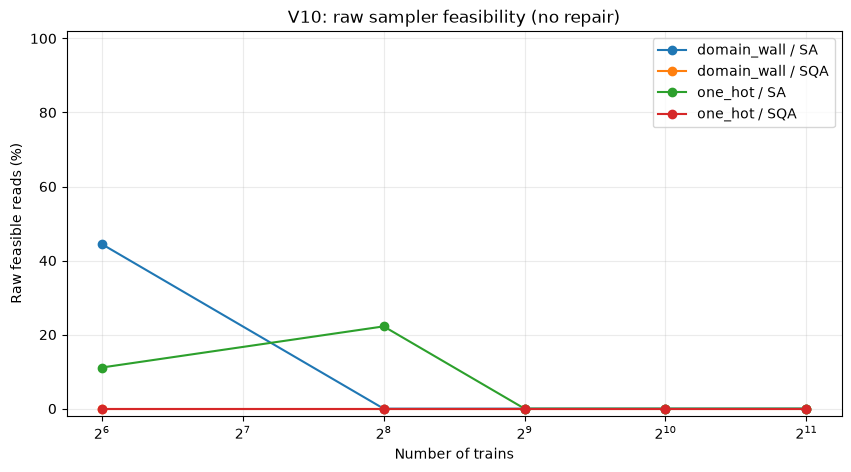

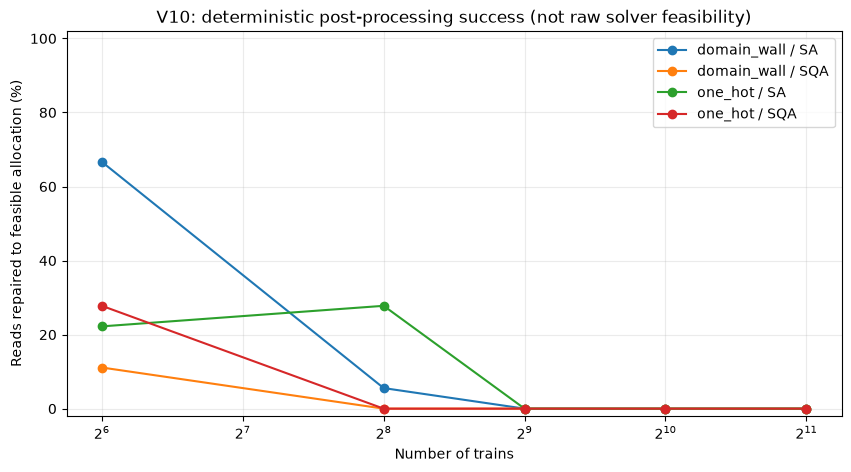

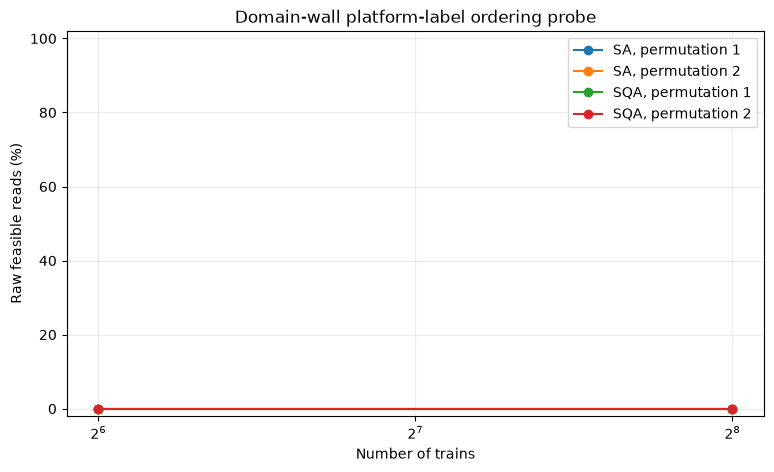

In [12]:
if not sampler_runs.empty:
    main_runs=sampler_runs[sampler_runs.phase=="MAIN"].copy()
    scaling_summary=(main_runs.groupby(["n_trains","encoding","algorithm"],dropna=False)
        .agg(datasets=("dataset_id","nunique"),sampler_runs=("run_status","size"),
             successful_runs=("run_status",lambda x:int((x=="OK").sum())),
             datasets_with_raw_valid=("best_raw_valid_cost",lambda x:int(x.notna().groupby(main_runs.loc[x.index,"dataset_id"]).any().sum())),
             mean_raw_feasibility_pct=("raw_feasibility_pct","mean"),
             median_raw_feasibility_pct=("raw_feasibility_pct","median"),
             mean_repair_success_pct=("repair_success_pct","mean"),
             mean_best_raw_valid_cost=("best_raw_valid_cost","mean"),
             mean_best_repaired_cost=("best_repaired_cost","mean"),
             median_runtime_s=("runtime_s","median"),
             wins_raw_over_greedy=("gap_best_raw_valid_to_best_greedy",lambda x:int((x<0).sum())),
             wins_repaired_over_greedy=("gap_best_repaired_to_best_greedy",lambda x:int((x<0).sum())))
        .reset_index())

    by_dataset=(main_runs.groupby(["dataset_id","n_trains","difficulty","encoding","algorithm"])
        .agg(mean_raw_feasibility_pct=("raw_feasibility_pct","mean"),
             best_raw_valid_cost=("best_raw_valid_cost","min"),
             mean_repair_success_pct=("repair_success_pct","mean"),
             best_repaired_cost=("best_repaired_cost","min"),
             median_runtime_s=("runtime_s","median")).reset_index())
    encoding_paired=(by_dataset.pivot_table(index=["dataset_id","n_trains","difficulty","algorithm"],
        columns="encoding",values=["mean_raw_feasibility_pct","best_raw_valid_cost",
        "mean_repair_success_pct","best_repaired_cost","median_runtime_s"],aggfunc="first").reset_index())
    encoding_paired.columns=["_".join([str(x) for x in c if str(x) not in ("","None")]).rstrip("_")
        if isinstance(c,tuple) else str(c) for c in encoding_paired.columns]

    repair_summary=(main_runs.groupby(["n_trains","encoding","algorithm"])
        .agg(mean_raw_feasibility_pct=("raw_feasibility_pct","mean"),
             mean_repair_success_pct=("repair_success_pct","mean"),
             mean_best_raw_valid_cost=("best_raw_valid_cost","mean"),
             mean_best_repaired_cost=("best_repaired_cost","mean"),
             repaired_runs=("best_repaired_cost",lambda x:int(x.notna().sum())),
             mean_domain_wall_order_transitions=("mean_domain_wall_order_violation_transitions_per_read","mean"),
             mean_constraint_violations=("mean_total_constraint_violations_per_read","mean"))
        .reset_index())

    greedy_comparison=(dataset_diagnostics.groupby("n_trains").agg(
        datasets=("dataset_id","nunique"),
        interval_greedy_feasible_rate=("greedy_interval_feasible","mean"),
        mrv_greedy_feasible_rate=("greedy_mrv_feasible","mean"),
        interval_greedy_mean_cost=("greedy_interval_cost","mean"),
        mrv_greedy_mean_cost=("greedy_mrv_cost","mean"),
        best_greedy_mean_cost=("best_greedy_cost","mean")).reset_index())

    print("Main scaling summary:"); display(scaling_summary)
    print("Paired encoding comparison (same dataset and algorithm):"); display(encoding_paired.head(20))
    print("Separate raw versus repaired summary:"); display(repair_summary)
    print("Greedy baselines:"); display(greedy_comparison)

    # Plot 1: raw feasibility — the primary, unrepaired measure.
    fig,ax=plt.subplots(figsize=(10,5))
    for (enc,alg),d in scaling_summary.groupby(["encoding","algorithm"]):
        d=d.sort_values("n_trains")
        ax.plot(d.n_trains,d.mean_raw_feasibility_pct,marker="o",label=f"{enc} / {alg}")
    ax.set_xscale("log",base=2); ax.set_ylim(-2,102); ax.set_xlabel("Number of trains")
    ax.set_ylabel("Raw feasible reads (%)"); ax.set_title("V10: raw sampler feasibility (no repair)")
    ax.grid(alpha=.25); ax.legend(); plt.show()

    # Plot 2: repair success, clearly labelled as post-processing.
    fig,ax=plt.subplots(figsize=(10,5))
    for (enc,alg),d in scaling_summary.groupby(["encoding","algorithm"]):
        d=d.sort_values("n_trains")
        ax.plot(d.n_trains,d.mean_repair_success_pct,marker="o",label=f"{enc} / {alg}")
    ax.set_xscale("log",base=2); ax.set_ylim(-2,102); ax.set_xlabel("Number of trains")
    ax.set_ylabel("Reads repaired to feasible allocation (%)")
    ax.set_title("V10: deterministic post-processing success (not raw solver feasibility)")
    ax.grid(alpha=.25); ax.legend(); plt.show()

    # Plot 3: domain-wall platform ordering sensitivity.
    if not platform_order_runs.empty:
        fig,ax=plt.subplots(figsize=(9,5))
        z=platform_order_runs.groupby(["n_trains","algorithm","platform_permutation_index"]).raw_feasibility_pct.mean().reset_index()
        for (alg,perm),d in z.groupby(["algorithm","platform_permutation_index"]):
            ax.plot(d.n_trains,d.raw_feasibility_pct,marker="o",label=f"{alg}, permutation {perm}")
        ax.set_xscale("log",base=2); ax.set_ylim(-2,102); ax.set_xlabel("Number of trains")
        ax.set_ylabel("Raw feasible reads (%)"); ax.set_title("Domain-wall platform-label ordering probe")
        ax.grid(alpha=.25); ax.legend(); plt.show()
else:
    scaling_summary=encoding_paired=repair_summary=greedy_comparison=pd.DataFrame()

## 12. Export results and metadata

PILOT and FULL are exported to separate directories. Retain all CSVs, metadata and the executed notebook together.

In [13]:
OUTPUT_DIR=Path.cwd()/f"railway_v10_outputs_{STUDY_MODE.lower()}"
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)

def export_frame(frame,name):
    if frame is None or frame.empty:
        print("Not exported (empty):",name); return
    path=OUTPUT_DIR/name; frame.to_csv(path,index=False); print("Saved:",path)

export_frame(dataset_diagnostics,"railway_v10_dataset_diagnostics.csv")
export_frame(generated_train_tables,"railway_v10_generated_train_tables.csv")
export_frame(conflict_edge_tables,"railway_v10_conflict_edges.csv")
export_frame(qubo_model_metrics,"railway_v10_qubo_model_metrics.csv")
export_frame(sampler_runs,"railway_v10_sampler_runs.csv")
export_frame(raw_sample_diagnostics_table,"railway_v10_raw_sample_diagnostics.csv")
export_frame(scaling_summary,"railway_v10_scaling_summary.csv")
export_frame(encoding_paired,"railway_v10_paired_encoding_comparison.csv")
export_frame(repair_summary,"railway_v10_repair_summary.csv")
export_frame(greedy_comparison,"railway_v10_greedy_comparison.csv")
export_frame(platform_order_runs,"railway_v10_platform_order_sensitivity.csv")

metadata={
    "notebook_version":"v10_final_encoding_and_feasibility_investigation",
    "study_mode":STUDY_MODE,"python_version":sys.version.split()[0],"platform":platform.platform(),
    "cpu":platform.processor(),"ram_gb":RAM_GB,"openjij_version":OPENJIJ_VERSION,
    "n_platforms":N_PLATFORMS,"long_platform_count":LONG_PLATFORM_COUNT,
    "long_train_coach_threshold":LONG_TRAIN_COACH_THRESHOLD,"clearance_min_assumption":CLEARANCE_MIN,
    "train_counts":TRAIN_COUNTS,"seeds_by_size":SEEDS_BY_SIZE,"difficulty_levels":DIFFICULTIES,
    "difficulty_config":DIFFICULTY_CONFIG,"dataset_count":len(dataset_diagnostics),
    "encodings":ENCODINGS,"algorithms":ALGORITHMS,"encoding_penalty_rules":{
        "one_hot":"U+1 for assignment and conflict penalties, where U is best validated feasible Greedy cost",
        "domain_wall":"conflict=U+1; monotonicity=(U+1)*(Rmax+1)*max_conflict_degree+U+2; eligibility is structural",
        "proof_note":"For train i, r_i forbidden 0-to-1 transitions imply indicator negative mass r_i and positive mass r_i+1. The per-edge conflict lower bound is -(Rmax+1)*(r_i+r_j); the reassignment objective is nonnegative because each individual platform indicator is at most one. The stated monotonicity penalty makes every wall-invalid state strictly more expensive than the feasible incumbent U. For wall-valid states, conflict=U+1 excludes conflicting states from the ground state."
    },
    "budgets":BUDGET_BY_SIZE,"repair_method":"sample-preference-guided deterministic MRV/degree greedy with bounded restarts; no witness or fallback Greedy is used",
    "repair_restarts":REPAIR_RESTARTS,"raw_vs_repaired":"Raw feasibility is always reported separately from repaired feasibility/cost",
    "platform_order_probe_datasets":ORDER_PROBE_DATASETS,"alternate_platform_orders_per_dataset":N_ALTERNATE_PLATFORM_ORDERS,
    "expected_dataset_count":EXPECTED_DATASETS,"planned_main_sampler_calls":EXPECTED_MAIN_CALLS,
    "planned_platform_order_calls":EXPECTED_ORDER_CALLS,"planned_total_sampler_calls":EXPECTED_CALLS,
    "actual_sampler_rows":len(sampler_runs),"sampler_error_rows":int((sampler_runs.run_status=="ERROR").sum()) if not sampler_runs.empty else 0,
    "resource_skips":0,"max_qubo_variables":MAX_QUBO_VARIABLES,"max_qubo_interactions":MAX_QUBO_INTERACTIONS,
    "synthetic_data_notice":"All schedules, delays, nominal platforms, coach counts and conflicts are synthetic; no station-specific dataset is used.",
    "witness_notice":"A known feasible witness is used only to validate the generator; it is never passed to either sampler or the repair decoder.",
    "quantum_notice":"OpenJij SQA is a classical simulation, not quantum hardware.",
    "exact_search_notice":"No exact search is run in V10 because the selected sizes start at 64; exact reference results for <=32 trains are retained from earlier versions.",
    "interpretation_notice":"A valid QUBO ground state does not imply finite-budget SA/SQA samples are valid. Repaired results are post-processing and must not be reported as raw sampler feasibility.",
}
with open(OUTPUT_DIR/"railway_v10_experiment_metadata.json","w",encoding="utf-8") as f: json.dump(metadata,f,indent=2)
print("V10 outputs saved to:",OUTPUT_DIR.resolve())

Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\railway_v10_outputs_full\railway_v10_dataset_diagnostics.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\railway_v10_outputs_full\railway_v10_generated_train_tables.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\railway_v10_outputs_full\railway_v10_conflict_edges.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\railway_v10_outputs_full\railway_v10_qubo_model_metrics.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\railway_v10_outputs_full\railway_v10_sampler_runs.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\railway_v10_outputs_full\railway_v10_raw_sample_diagnostics.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\railway_v10_outputs_full\railway_v10_scaling_summary.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\railway_v10_outputs_full\railway_v10_paired_encoding_comparison.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\railway_v10_outputs_full\railway_v10_repair_summary.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\

## 13. Final stopping and reporting checklist

- [ ] Pilot passes both encoding identity checks and exhaustive tiny ground-state tests.
- [ ] Pilot platform-label permutation preserves feasibility and objective cost.
- [ ] FULL includes all five pre-registered train sizes and all expected datasets.
- [ ] Every dataset has both QUBO encodings built, unless an explicitly recorded resource limit is reached.
- [ ] Both SA and SQA use identical reads, sweeps, repeats and paired seeds across encodings.
- [ ] Raw feasibility and repaired feasibility are reported separately.
- [ ] Every raw sample records cardinality, wall-order train counts, wall-rise transition counts, eligibility and conflict diagnostics independently.
- [ ] Repair never uses the witness or silently substitutes a Greedy assignment.
- [ ] Domain-wall platform-order sensitivity is reported as an exploratory robustness check.
- [ ] SQA is described as a classical simulation; no quantum-advantage claim is made.
- [ ] The V9/V9.1 results remain unchanged and are preserved as earlier experimental stages.

**Stopping rule:** after a valid V10 FULL run, finish the statistical analysis and paper. Do not create another scaling version or introduce another encoding unless a reproducible correctness defect is found.